# Disease Surveillance and Population Health: From Weekly Reports to Investigation Alerts

**Unit II — AI Applications Across the Healthcare Ecosystem**

**Prerequisites:** introductory pandas (`groupby`, `merge`), mean and standard deviation, sensitivity and positive predictive value (PPV).
**Companion lab:** [Lab 8 — Disease Surveillance and Population Health](../labs/lab-08-disease-surveillance-population-health.ipynb)

> All districts, reports, and outbreaks here are fictional, simulated by [`surveillance_fixture.py`](surveillance_fixture.py) with a fixed seed. They cannot estimate real disease burden or real detector performance.

## Learning objectives

1. Distinguish detection, forecasting, and risk stratification in population health.
2. Explain why a surveillance signal is not a confirmed outbreak, and how reporting shapes the data.
3. Build district-week indicators without treating missing reports as zero.
4. Build a leakage-free historical baseline and explain how unusual past weeks contaminate it.
5. Evaluate alerts by event detection, delay, and PPV, choosing thresholds on development data only.
6. Investigate an alert using facility-level and testing evidence.

## 1. Monday morning in a district surveillance unit

It is **Monday 16 February 2026**. Facilities in six fictional districts report weekly counts of people meeting a **suspected-case definition** for a fever illness, plus laboratory tests performed and positive. This week, two districts jumped. You have **one** field team.

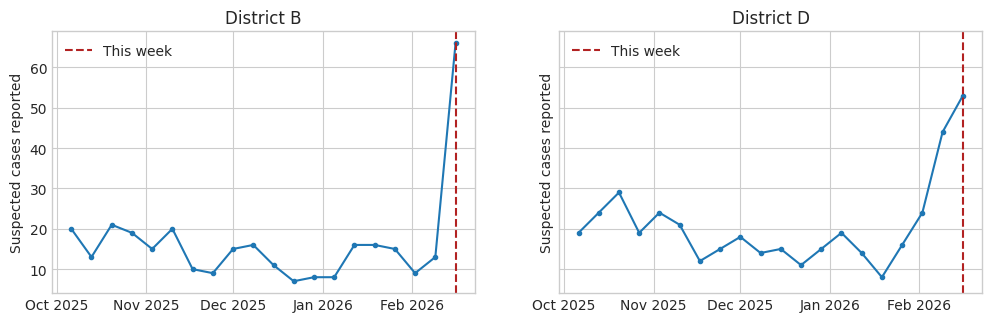

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from IPython.display import display

# The fixture module sits next to this notebook (second path: Jupyter started at repo root).
for folder in [Path.cwd(), Path.cwd() / "module2" / "lectures"]:
    if (folder / "surveillance_fixture.py").exists():
        sys.path.insert(0, str(folder))
        break
else:
    raise FileNotFoundError("Could not find surveillance_fixture.py next to this notebook.")
from surveillance_fixture import make_surveillance_fixture

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.width", 140)

data = make_surveillance_fixture()
districts, facility_register, reports_raw = data["districts"], data["facility_register"], data["reports_raw"]
event_truth, artifact_truth = data["event_truth"], data["artifact_truth"]   # unopened until Section 5
HOOK_WEEK = pd.Timestamp("2026-02-16")

quick = (reports_raw[reports_raw["week_start"] <= HOOK_WEEK]
         .groupby(["district", "week_start"])["suspected_cases"].sum().unstack("district"))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), sharey=True)
for ax, district in zip(axes, ["District B", "District D"]):
    recent = quick[district].loc["2025-10-01":]
    ax.plot(recent.index, recent.values, marker="o", markersize=3)
    ax.axvline(HOOK_WEEK, color="firebrick", linestyle="--", label="This week")
    ax.set_title(district)
    ax.set_ylabel("Suspected cases reported")
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
    ax.legend(loc="upper left")
plt.show()

**Commit to an answer:** which district gets the field team, and what would you want to know first? We return to this in Section 6.

## 2. What population-health analytics is asked to do

Population health looks at outcomes across places, periods, and groups rather than one patient. Three kinds of "predictive" task are common:

| Task | Question | Unit | Judged by |
|---|---|---|---|
| **Detection** | Is this week unusual enough to investigate? | District-week | Finding real events early without too many false alerts |
| **Forecasting** | How many cases next month? | District-month | Forecast error and honest uncertainty |
| **Risk stratification** | Who or where should get outreach first? | Person or area | Discrimination, calibration, reaching people in need |

This lecture focuses on **detection**. Its vocabulary:

| Term | Meaning |
|---|---|
| **Case definition** | Agreed criteria for counting a case. *Suspected* (symptoms only) is broad and fast; *confirmed* (laboratory) is specific and slow |
| **Signal** | Data that may indicate a threat |
| **Alert** | A signal that meets a pre-agreed rule for investigation |
| **Outbreak** | More cases than expected for a place and period, **established by investigation** |

An algorithm produces signals and alerts; only investigation establishes an outbreak. India's Integrated Disease Surveillance Programme (IDSP) works this way: weekly suspected (S), presumptive (P), and laboratory-confirmed (L) reports on the Integrated Health Information Platform (IHIP) are reviewed by district units, and Rapid Response Teams investigate ([NCDC](https://www.ncdc.mohfw.gov.in/includes/About/CentresAndDivision/IDSP.php)). Our fictional data are not an IHIP export.

## 3. How disease becomes data

```text
Infections in the community
 └─ symptoms noticed → care sought → case definition recognised → test done → report submitted on time
                                                                              └─ counted this week
```

People drop out at every step, so **"no signal" can mean low disease, poor access, little testing, or missing reports**. Three measures help separate these:

- **Reported rate per 100,000** = cases reported ÷ population × 100,000. It allows districts of different sizes to be compared, but it is *not* true incidence (new infections in the population at risk). Prevalence (all current cases at one time) is a different measure, used mostly for chronic disease.
- **Reporting completeness** = facilities that reported ÷ facilities expected. A facility reporting **0 cases** is an observation; a facility sending **no report** is missing. Never treat missing as zero.
- **Test positivity** = positive tests ÷ tests performed. If the target infection is really rising, positivity rises. If extra cases are other illnesses or late-entered old records, it stays at its usual level.

## 4. From facility reports to district-weeks

Each report is one **facility-week**. A facility that does not report leaves **no row**, so the facility register is the only record of who should have reported. The cell below:

1. removes an exact duplicate report;
2. builds a complete district × week grid (6 × 78 = 468 rows), so weeks with no reports do not silently disappear;
3. joins summed reports onto the grid, leaving cases **missing** where nobody reported; and
4. computes completeness, reported rate, and positivity.

In [2]:
reports = reports_raw.drop_duplicates().copy()        # the one duplicate is an exact copy
assert not reports.duplicated(["facility_id", "week_start"]).any()

expected = facility_register.groupby("district").size().rename("facilities_expected").reset_index()
grid = expected.merge(districts, on="district").merge(
    pd.DataFrame({"week_start": sorted(reports["week_start"].unique())}), how="cross")

summed = reports.groupby(["district", "week_start"], as_index=False).agg(
    facilities_reporting=("facility_id", "nunique"),
    suspected_cases=("suspected_cases", "sum"),
    tests_performed=("tests_performed", "sum"),
    laboratory_positive=("laboratory_positive", "sum"),
)
weekly = (grid.merge(summed, on=["district", "week_start"], how="left", validate="one_to_one")
          .sort_values(["district", "week_start"]).reset_index(drop=True))
weekly["facilities_reporting"] = weekly["facilities_reporting"].fillna(0).astype(int)

weekly["reporting_completeness"] = weekly["facilities_reporting"] / weekly["facilities_expected"]
weekly["reported_suspected_rate_per_100k"] = weekly["suspected_cases"] / weekly["population"] * 100_000
weekly["test_positivity"] = weekly["laboratory_positive"] / weekly["tests_performed"].where(weekly["tests_performed"] > 0)

print(f"Reports: {len(reports_raw)} received, {len(reports)} after removing the duplicate")
print(f"District-week rows: {len(weekly)}")
display(weekly.loc[weekly["suspected_cases"].isna(), ["district", "week_start", "facilities_reporting", "suspected_cases"]])

Reports: 3536 received, 3535 after removing the duplicate
District-week rows: 468


,district,week_start,facilities_reporting,suspected_cases
399,District F,2025-03-10,0,NaN


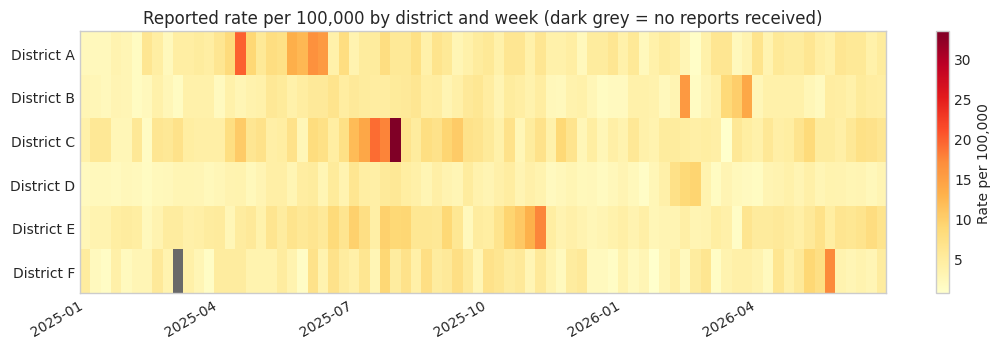

In [3]:
rate_matrix = weekly.pivot(index="district", columns="week_start", values="reported_suspected_rate_per_100k")
cmap = plt.get_cmap("YlOrRd").copy()
cmap.set_bad("dimgrey")
fig, ax = plt.subplots(figsize=(13, 3.4))
image = ax.imshow(rate_matrix, aspect="auto", cmap=cmap)
ax.grid(False)
ax.set_yticks(range(len(rate_matrix.index)), rate_matrix.index)
ticks = np.arange(0, rate_matrix.shape[1], 13)
ax.set_xticks(ticks, [rate_matrix.columns[i].strftime("%Y-%m") for i in ticks], rotation=30, ha="right")
ax.set_title("Reported rate per 100,000 by district and week (dark grey = no reports received)")
fig.colorbar(image, ax=ax, label="Rate per 100,000")
plt.show()

The one district-week with no reports stays missing (dark grey) rather than appearing as a quiet week. The heatmap shows bursts of different shapes, but cannot tell us *why* any week is high.

## 5. Detecting unusual weeks

### A baseline and a z-score

A **baseline** describes what a district reports under ordinary conditions. If the previous four weekly rates were 4, 5, 3, and 4 (mean 4, SD 0.82) and this week is 8:

$$
z = \frac{\text{this week} - \text{baseline mean}}{\text{baseline SD}} = \frac{8 - 4}{0.82} \approx 4.9
$$

This week is about 4.9 typical fluctuations above normal: a **signal**, not proof of an outbreak.

For every district-week we use the **previous 8 weeks** of the same district. `shift(1)` excludes the current week from its own baseline, preventing leakage, and at least 4 past weeks are required.

In [4]:
by_district = weekly.groupby("district")["reported_suspected_rate_per_100k"]
weekly["baseline_mean"] = by_district.transform(lambda s: s.shift(1).rolling(8, min_periods=4).mean())
weekly["baseline_sd"] = by_district.transform(lambda s: s.shift(1).rolling(8, min_periods=4).std())
weekly["z_score"] = (weekly["reported_suspected_rate_per_100k"] - weekly["baseline_mean"]) / weekly["baseline_sd"].replace(0, np.nan)

### From signal to alert

A fictional alert policy turns a signal into an action only if the data can be trusted:

| Status | Condition | Action |
|---|---|---|
| `CHECK DATA QUALITY` | Counts missing or completeness < 80% | Contact facilities first; a quiet week with half the facilities missing is not reassuring |
| `INVESTIGATE SIGNAL` | z above threshold **and** ≥ 5 cases **and** data quality OK | Verify (Section 6) |
| `NO AUTOMATIC ALERT` | Otherwise | Routine monitoring |

In [5]:
def apply_alert_policy(frame, z_threshold, z_column="z_score"):
    # Statistical, size, and data-quality rules. Never uses truth labels.
    result = frame.copy()
    result["data_quality_flag"] = result["suspected_cases"].isna() | (result["reporting_completeness"] < 0.80)
    result["investigation_alert"] = ((result[z_column] > z_threshold)
                                     & (result["suspected_cases"] >= 5) & ~result["data_quality_flag"])
    result["status"] = np.select([result["data_quality_flag"], result["investigation_alert"]],
                                 ["CHECK DATA QUALITY", "INVESTIGATE SIGNAL"], default="NO AUTOMATIC ALERT")
    return result

apply_alert_policy(weekly, z_threshold=2.5)["status"].value_counts().to_frame("district-weeks")

,district-weeks
status,
NO AUTOMATIC ALERT,428
INVESTIGATE SIGNAL,25
CHECK DATA QUALITY,15


### How do we score alerts?

Only now do we attach the simulation's truth: which district-weeks were inside a real event. Investigators need **one timely alert per event**, so we score at two levels:

- **Event detection** = events with at least one alert ÷ all events. **Detection delay** = first alert week − event start week (0 = alerted in the first week).
- **Alert PPV** = alerts inside an event ÷ all alerts. Low PPV means wasted field visits.

We split by time: **development** (first 52 weeks) for diagnosing problems and choosing settings, and **test** (last 26 weeks), opened **once** at the end.

In [6]:
def evaluate(frame, z_threshold, z_column="z_score"):
    # Alert, attach truth afterwards, and score events and alerts.
    scored = (apply_alert_policy(frame, z_threshold, z_column)
              .merge(event_truth, on=["district", "week_start"], how="left", validate="one_to_one"))
    scored = scored[scored[z_column].notna()]                 # weeks that had a baseline
    alert, in_event = scored["investigation_alert"], scored["event_id"].notna()
    first_alert = scored[alert].groupby("event_id")["week_start"].min()
    onset = scored[in_event].groupby("event_id")["week_start"].min()
    delays = ((first_alert.reindex(onset.index) - onset).dt.days // 7).rename("delay_weeks")
    summary = {"events detected": f"{delays.notna().sum()}/{len(delays)}",
               "worst delay": delays.max(),
               "false alerts": int((alert & ~in_event).sum()),
               "alert PPV": round((alert & in_event).sum() / alert.sum(), 2)}
    return summary, delays

cutoff = weekly["week_start"].min() + pd.Timedelta(weeks=52)
development, test = weekly[weekly["week_start"] < cutoff], weekly[weekly["week_start"] >= cutoff]

summary, delays = evaluate(development, 2.5)
print(summary)
delays.to_frame()   # missing delay = event never detected

{'events detected': '3/4', 'worst delay': 3.0, 'false alerts': 10, 'alert PPV': 0.41}


,delay_weeks
event_id,
DEV-A-1,0.0
DEV-A-2,NaN
DEV-C-1,0.0
DEV-E-1,3.0


**DEV-A-2 was never detected.** Because this happened in the development period, we may investigate it and change the method.

### Lesson 1: an unusual past week contaminates the baseline

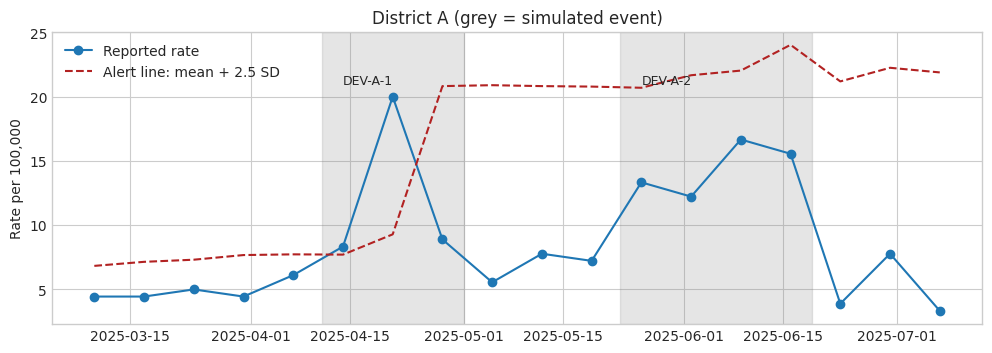

In [7]:
a = weekly.merge(event_truth, on=["district", "week_start"], how="left")
a = a[(a["district"] == "District A") & a["week_start"].between("2025-03-10", "2025-07-07")]
fig, ax = plt.subplots(figsize=(12, 3.8))
for event_id, rows in a.dropna(subset=["event_id"]).groupby("event_id"):
    ax.axvspan(rows["week_start"].min() - pd.Timedelta(days=3), rows["week_start"].max() + pd.Timedelta(days=3),
               color="grey", alpha=0.2)
    ax.text(rows["week_start"].min(), 21, event_id, fontsize=9)
ax.plot(a["week_start"], a["reported_suspected_rate_per_100k"], marker="o", label="Reported rate")
ax.plot(a["week_start"], a["baseline_mean"] + 2.5 * a["baseline_sd"], "--", color="firebrick",
        label="Alert line: mean + 2.5 SD")
ax.set_ylabel("Rate per 100,000")
ax.set_title("District A (grey = simulated event)")
ax.legend(loc="upper left")
plt.show()

The 21 April spike (rate 20) stays in the 8-week baseline window. The baseline SD jumps from about 1.7 to about 5.6, the alert line rises above 20, and DEV-A-2's clearly raised rates (12–17) never reach it. **One outbreak hid the next.** A reporting backlog would do the same.

**Fix: a quality-aware baseline.** Build each week's baseline from the last 8 *usable* weeks, where a week is not usable if:

- completeness was below 80% (its count is untrustworthy), or
- its own z-score exceeded **4** (clearly abnormal).

Why 4 and not the alert threshold? Excluding every mildly high week leaves only low weeks in the history. The SD then shrinks, more weeks look high, and still more are excluded, flooding investigators with false alerts. Established surveillance algorithms also down-weight past outbreak weeks ([Noufaily et al., 2013](https://doi.org/10.1002/sim.5595)).

In [8]:
def quality_aware_z(frame, window=8, min_history=4, exclude_above=4.0):
    # z-score against the last `window` usable weeks; exclusion depends on earlier weeks, so we loop.
    z_values = pd.Series(np.nan, index=frame.index)
    for _, rows in frame.groupby("district"):
        history = []
        for index, row in rows.iterrows():
            rate = row["reported_suspected_rate_per_100k"]
            if len(history) >= min_history and pd.notna(rate):
                recent = np.array(history[-window:])
                if recent.std(ddof=1) > 0:
                    z_values[index] = (rate - recent.mean()) / recent.std(ddof=1)
            trustworthy = pd.notna(rate) and row["reporting_completeness"] >= 0.80
            if trustworthy and not z_values[index] > exclude_above:
                history.append(rate)
    return z_values

weekly["clean_z"] = quality_aware_z(weekly)
development, test = weekly[weekly["week_start"] < cutoff], weekly[weekly["week_start"] >= cutoff]

pd.DataFrame({"rolling baseline": evaluate(development, 2.5)[1],
              "quality-aware baseline": evaluate(development, 2.5, "clean_z")[1]}
            ).rename_axis("delay (weeks) by event")

,rolling baseline,quality-aware baseline
delay (weeks) by event,,
DEV-A-1,0.0,0
DEV-A-2,NaN,0
DEV-C-1,0.0,0
DEV-E-1,3.0,2


The quality-aware baseline detects all four development events, including DEV-A-2 in its first week, with one extra false alert (11 versus 10).

### Choosing the threshold with a rule written in advance

Lower thresholds alert sooner but send more false alerts. Our fictional rule: **every development event detected within 2 weeks; then the fewest false alerts.**

In [9]:
threshold_table = pd.DataFrame({t: evaluate(development, t, "clean_z")[0] for t in [2.0, 2.5, 3.0, 3.5]}).T
display(threshold_table.rename_axis("z threshold"))

meets_rule = (threshold_table["events detected"] == "4/4") & (threshold_table["worst delay"] <= 2)
SELECTED_THRESHOLD = threshold_table.loc[meets_rule, "false alerts"].astype(int).idxmin()
print("Selected threshold:", SELECTED_THRESHOLD)

,events detected,worst delay,false alerts,alert PPV
z threshold,,,,
2.0,4/4,1,21,0.38
2.5,4/4,2,11,0.5
3.0,4/4,3,8,0.53
3.5,4/4,3,5,0.55


Selected threshold: 2.5


Halving false alerts (21 → 11) costs one week of delay. Going above 2.5 breaks the 2-week rule. The rule makes this judgement explicit and reviewable. A team with more investigators might accept 2.0.

### Open the test period once

In [10]:
test_summary, test_delays = evaluate(test, SELECTED_THRESHOLD, "clean_z")
print(test_summary)

# 95% Wilson interval for the event detection rate
k, n, z = test_delays.notna().sum(), len(test_delays), 1.96
centre = (k / n + z**2 / (2 * n)) / (1 + z**2 / n)
half = z * np.sqrt(k / n * (1 - k / n) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
print(f"95% interval for detection rate: {centre - half:.0%} to {centre + half:.0%}")

pd.DataFrame({"rolling baseline (not used for any choice)": evaluate(test, SELECTED_THRESHOLD)[1],
              "quality-aware baseline (frozen method)": test_delays}).rename_axis("delay (weeks) by event")

{'events detected': '3/3', 'worst delay': 1, 'false alerts': 4, 'alert PPV': 0.69}
95% interval for detection rate: 44% to 100%


,rolling baseline (not used for any choice),quality-aware baseline (frozen method)
delay (weeks) by event,,
TEST-B-1,NaN,1
TEST-D-1,0.0,0
TEST-F-1,0.0,0


The frozen method detects all three test events, with roughly 7 in 10 alerts real. But **3/3 is consistent with a true detection rate anywhere from about 44% to 100%**: three events are weak evidence, and simulated events are cleaner than real ones. This is not public-health validation.

The rolling baseline, shown only for illustration, misses TEST-B-1. That happens because of the District B spike on 16 February, one of our two Monday-morning alerts.

## 6. Investigate the two Monday-morning alerts

Back to 16 February, using only data available that morning. Both B and D are `INVESTIGATE SIGNAL`. An alert starts verification. Check: is the increase **concentrated in one facility**? Did **positivity** change? Is it **building** over weeks?

In [11]:
board = apply_alert_policy(weekly, SELECTED_THRESHOLD, "clean_z")
display(board.loc[board["week_start"].eq(HOOK_WEEK) & board["district"].isin(["District B", "District D"]),
                  ["district", "suspected_cases", "clean_z", "reporting_completeness", "status"]].round(2))

for district in ["District B", "District D"]:
    week = reports[(reports["district"] == district) & (reports["week_start"] == HOOK_WEEK)]
    top = week.loc[week["suspected_cases"].idxmax()]
    usual = reports[(reports["facility_id"] == top["facility_id"])
                    & reports["week_start"].between(HOOK_WEEK - pd.Timedelta(weeks=8), HOOK_WEEK, inclusive="left")]
    print(f"{district}: {len(week)} facilities reported; largest is {top['facility_id']} with "
          f"{top['suspected_cases'] / week['suspected_cases'].sum():.0%} of cases "
          f"(its usual weekly mean: {usual['suspected_cases'].mean():.1f})")

recent = weekly[weekly["district"].isin(["District B", "District D"])
                & weekly["week_start"].between(HOOK_WEEK - pd.Timedelta(weeks=4), HOOK_WEEK)]
recent.pivot(index="week_start", columns="district", values=["suspected_cases", "test_positivity"]).round(2)

,district,suspected_cases,clean_z,reporting_completeness,status
136,District B,66.0,14.01,0.9,INVESTIGATE SIGNAL
292,District D,53.0,7.81,1.0,INVESTIGATE SIGNAL


District B: 9 facilities reported; largest is B-01 with 80% of cases (its usual weekly mean: 0.9)
District D: 12 facilities reported; largest is D-02 with 13% of cases (its usual weekly mean: 2.0)


suspected_cases            test_positivity           
district        District B District D      District B District D
week_start                                                      
2026-01-19            16.0        8.0            0.00       0.00
2026-01-26            15.0       16.0            0.00       0.00
2026-02-02             9.0       24.0            0.25       0.12
2026-02-09            13.0       44.0            0.00       0.42
2026-02-16            66.0       53.0            0.10       0.42

| | District B | District D |
|---|---|---|
| Spread | One facility (B-01) supplies 80% of cases; it usually reports about 1 a week | Spread across all 12 facilities |
| Positivity | About 10%, near the background level | Rose to about 40% |
| Trend | A single jump | Building over three weeks |
| **Next step** | Phone B-01: data-entry backlog? Ask for onset dates | **Send the field team**; get line list, admissions, neighbouring districts |

These checks can still mislead, for example if testing policy changes or a different pathogen is circulating. Now reveal the truth:

In [12]:
(weekly[weekly["week_start"] == HOOK_WEEK][["district", "week_start"]]
 .merge(event_truth, how="left").merge(artifact_truth, how="left")
 .query("district in ['District B', 'District D']"))

,district,week_start,event_id,artifact_label
1,District B,2026-02-16,NaN,Delayed reports entered as a one-week backlog
3,District D,2026-02-16,TEST-D-1,NaN


District B was a **delayed-entry backlog**; District D was in the third week of a **real outbreak**. A month later District B had a genuine outbreak, caught only because the quality-aware baseline did not let the backlog distort "normal". The chart in Section 1 could not tell these apart; completeness, facility detail, and testing data could.

## 7. Beyond the detector

- **Evaluate the whole system.** CDC's guidelines judge surveillance on usefulness, simplicity, flexibility, data quality, acceptability, sensitivity, PPV, representativeness, timeliness, and stability ([CDC, 2001](https://www.cdc.gov/mmwr/preview/mmwrhtml/rr5013a1.htm)). A good detector on delayed, incomplete, or unrepresentative data is still a weak system.
- **Where AI and machine learning (ML) can help:** forecasting expected counts with seasonal features, combining cases, tests, and admissions to separate artifacts from outbreaks (what we did by hand), triaging unstructured event reports, and flagging backlogs and duplicates. Each must use only information available before the alert week, and must beat a transparent baseline like ours under temporal evaluation.
- **Equity.** A quiet district may have poor access or missing reports, not low disease. Check completeness and alert behaviour by district and group.

### Key takeaways

1. Detection, forecasting, and risk stratification are different tasks with different evaluations.
2. Surveillance counts reflect care-seeking, testing, and reporting. Missing is not zero, and "no signal" is not "no disease".
3. Build from a complete district × week grid; use only past weeks for the baseline.
4. Unusual past weeks, real or artifactual, can hide the next event. Keep them out of "normal".
5. Choose settings with explicit rules on development data, open the test period once, and report uncertainty.
6. An alert starts verification; facility detail and testing patterns separate artifacts from outbreaks.

### Review questions

1. Why is the variable called a *reported* suspected-case rate rather than incidence?
2. A district reports 0 cases with 3 of 8 facilities reporting. What should the dashboard show?
3. What leakage does `shift(1)` prevent?
4. Using District A, explain how one outbreak can hide the next.
5. Why was the threshold chosen on development data, and what does the 44–100% interval tell you?
6. Name three checks that separated District B's backlog from District D's outbreak.

**Further practice:** Lab 8 applies this workflow to a different fictional region. Optional extensions: a median-based baseline, a seasonal count model, or repeating the simulation with other seeds (`make_surveillance_fixture(seed=...)`).

### References

- National Centre for Disease Control. [Integrated Disease Surveillance Programme](https://www.ncdc.mohfw.gov.in/includes/About/CentresAndDivision/IDSP.php). Government of India.
- World Health Organization (2014). [Early detection, assessment and response to acute public health events](https://www.who.int/publications/i/item/WHO-HSE-GCR-LYO-2014.4).
- German RR, et al. (2001). [Updated guidelines for evaluating public health surveillance systems](https://www.cdc.gov/mmwr/preview/mmwrhtml/rr5013a1.htm). *MMWR*, 50(RR-13).
- CDC. [Principles of Epidemiology, Lesson 3: Measures of Risk](https://archive.cdc.gov/www_cdc_gov/csels/dsepd/ss1978/lesson3/section2.html).
- Noufaily A, et al. (2013). [An improved algorithm for outbreak detection in multiple surveillance systems](https://doi.org/10.1002/sim.5595). *Statistics in Medicine*, 32(7), 1206–1222.